# 06 · Números e figuras do artigo (seções 3 e 4)

**Objetivo.** Calcular os números do artigo que não estão nas saídas dos notebooks 01 a 05, repetir as verificações automáticas do piloto e gerar as Figuras 1, 3 e 4, sem alterar os notebooks anteriores nem os arquivos que eles gravam.

- **Lê:** `../data/repository.parquet`, `../data/pull_request.parquet`, `../data/pr_commits.parquet`, `../out/candidatos.csv`, `../out/piloto.csv`, `../out/atribuicao_resumo.csv`, `../out/<projeto>/log.txt`, `../out/<projeto>/commits_atribuidos.csv`, `../out/<projeto>/arquivos_mensais.parquet`, `../out/alteracoes.csv`, `../out/avisos_introduzidos.csv`, `../out/qp2_taxas.csv`, `../out/qp2_por_projeto.csv`, `../out/qp3_intensidade.csv`, `../out/qp3_por_agente.csv` e os clones em `../repos/<projeto>/` (via `git`)
- **Grava:** `../out/artigo_amostra.csv`, `../out/artigo_composicao.csv`, `../out/artigo_sensibilidade_testes.csv`, `../out/artigo_qp1_complexidade_kloc.csv`, `../out/artigo_qp2_kloc_projeto.csv`, `../out/artigo_qp3_projeto.csv`, `../out/artigo_qp4_projeto.csv`, `../out/artigo_qp4_familias.csv`, `../out/figs/fig1_pipeline.png`, `../out/figs/qp2_taxas.png` e `../out/figs/qp3_por_agente.png`

Nos caminhos, `<projeto>` é o nome do repositório com `/` trocado por `__`.

**O que esta célula faz.** Importa as bibliotecas, define os caminhos e funções auxiliares (Git, leitura de *blobs* e contagem de avisos do Ruff com as mesmas regras dos notebooks 03 e 04) e carrega as tabelas de resumo do piloto.

In [1]:
import io, json, os, platform, re, subprocess, sys, tempfile, warnings
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch
from matplotlib.ticker import FuncFormatter
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=SyntaxWarning)

RUFF_SELECT = 'F,E,B,SIM,C90,PLE,PLW,PLR,PLC,ERA'
RUFF_IGNORE = 'E501,PLR2004,PLC0415'
EXCL = re.compile(r'(^|/)(\.venv|venv|env|site-packages|node_modules|vendor|third_party|build|dist|\.tox)/')
TESTE = r'(?:^|/)(?:tests?|testing)/|(?:^|/)test_[^/]*\.py$|_test\.py$|(?:^|/)conftest\.py$'   # arquivo de teste
chave = lambda n: n.replace('/', '__')
curto = lambda n: n.split('/')[1]
virg = lambda x, d=1: f'{x:.{d}f}'.replace('.', ',')

piloto = pd.read_csv('../out/piloto.csv')
REPOS = list(piloto.full_name)
resumo = pd.read_csv('../out/atribuicao_resumo.csv').set_index('projeto')
adocao = pd.to_datetime(resumo.adocao, utc=True)

def git(repo, *args, entrada=None):
    r = subprocess.run(['git', '-C', repo, *args], capture_output=True, input=entrada)
    if r.returncode != 0:
        raise RuntimeError(r.stderr.decode('utf-8', 'replace')[:300])
    return r.stdout

def ler_blobs(repo, blobs):
    saida = git(repo, 'cat-file', '--batch', entrada=('\n'.join(blobs) + '\n').encode())
    conteudo, i = {}, 0
    while i < len(saida):
        fim = saida.index(b'\n', i)
        sha, _, tam = saida[i:fim].decode().split()
        tam = int(tam)
        conteudo[sha] = saida[fim + 1: fim + 1 + tam].decode('utf-8', 'replace')
        i = fim + 1 + tam + 1
    return conteudo

def avisos_no_commit(repo, sha):
    """Avisos do Ruff (mesmas regras do estudo) somados em todos os .py da árvore de um commit."""
    blobs = []
    for l in git(repo, 'ls-tree', '-r', '-z', sha).decode('utf-8', 'replace').split('\0'):
        if l:
            meta, caminho = l.split('\t', 1)
            tipo, blob = meta.split()[1:3]
            if tipo == 'blob' and caminho.endswith('.py') and not EXCL.search(caminho):
                blobs.append(blob)
    conteudo = ler_blobs(repo, sorted(set(blobs)))
    with tempfile.TemporaryDirectory() as tmp:
        for b, src in conteudo.items():
            open(os.path.join(tmp, b + '.py'), 'w', encoding='utf-8').write(src)
        r = subprocess.run([sys.executable, '-m', 'ruff', 'check', '--isolated', '--no-cache', '--exit-zero',
                            '--output-format', 'json', '--select', RUFF_SELECT, '--ignore', RUFF_IGNORE, tmp],
                           capture_output=True, text=True)
    por_blob = pd.Series([os.path.basename(a['filename'])[:-3] for a in json.loads(r.stdout or '[]') if a['code']]).value_counts()
    return int(sum(por_blob.get(b, 0) for b in blobs))
print('Projetos:', [curto(r) for r in REPOS])

Projetos: ['numbagg', 'HARK', 'DDNS', 'diffyscan', 'PyAirbyte']


**O que esta célula faz.** Registra as versões do Python, das bibliotecas, do Ruff, do Radon e do Git e o equipamento, para a Tabela 3 do artigo.

In [2]:
import lifelines, radon, scipy, statsmodels, pyarrow
ruff_v = subprocess.run([sys.executable, '-m', 'ruff', '--version'], capture_output=True, text=True).stdout.strip()
radon_v = subprocess.run([os.path.join(os.path.dirname(sys.executable), 'radon'), '--version'], capture_output=True, text=True).stdout.strip()
git_v = subprocess.run(['git', '--version'], capture_output=True, text=True).stdout.strip()
mem = int(subprocess.run(['sysctl', '-n', 'hw.memsize'], capture_output=True, text=True).stdout) / 2**30
cpu = subprocess.run(['sysctl', '-n', 'machdep.cpu.brand_string'], capture_output=True, text=True).stdout.strip()
versoes = {'Python': platform.python_version(), 'pandas': pd.__version__, 'NumPy': np.__version__, 'pyarrow': pyarrow.__version__,
           'matplotlib': matplotlib.__version__, 'SciPy': scipy.__version__, 'statsmodels': statsmodels.__version__,
           'lifelines': lifelines.__version__, 'Radon': radon_v, 'Ruff': ruff_v, 'Git': git_v,
           'Sistema': f'macOS {platform.mac_ver()[0]}', 'Processador': cpu, 'Memória (GB)': round(mem)}
pd.Series(versoes, name='versão').to_frame()

,versão
Python,3.12.16
pandas,2.3.3
NumPy,2.5.4
pyarrow,26.0.0
matplotlib,3.11.2
SciPy,1.18.1
statsmodels,0.15.0
lifelines,0.30.3
Radon,6.0.1
Ruff,ruff 0.16.8


**O que esta célula faz.** Refaz o funil de seleção a partir das tabelas do AIDev v3: total de repositórios, repositórios Python, os que têm ao menos um PR de agente aceito e os candidatos (pelo menos 5 PRs aceitos). Também confere o número de estrelas mínimo do subconjunto curado, o período coberto pelos PRs e se `candidatos.csv` tem o mesmo número de linhas.

In [3]:
repo = pd.read_parquet('../data/repository.parquet')
pr = pd.read_parquet('../data/pull_request.parquet')
pc = pd.read_parquet('../data/pr_commits.parquet')
aceitos = pr[pr.merged_at.notna()]
py = repo[repo.language == 'Python']
n_py = aceitos[aceitos.repo_id.isin(py.id)].groupby('repo_id').size()
cand = pd.read_csv('../out/candidatos.csv')
funil = pd.DataFrame([
    ('Repositórios no subconjunto curado do AIDev v3', len(repo)),
    ('Em Python', len(py)),
    ('Em Python com ao menos 1 PR de agente aceito', len(n_py)),
    ('Candidatos: ao menos 5 PRs de agente aceitos', int((n_py >= 5).sum())),
    ('Piloto', len(piloto))], columns=['etapa', 'repositórios'])
display(funil)
print('Linhas em candidatos.csv:', len(cand), '| estrelas mínimas no subconjunto:', repo.stars.min())
print('Tabelas: repository', len(repo), '| pull_request', len(pr), '| pr_commits', len(pc))
print('PRs criados de', pr.created_at.min()[:10], 'a', pr.created_at.max()[:10], '| último merge', aceitos.merged_at.max()[:10])
print('Agente mais frequente nos candidatos:', cand.agente.value_counts().to_dict())

,etapa,repositórios
0,Repositórios no subconjunto curado do AIDev v3,2807
1,Em Python,530
2,Em Python com ao menos 1 PR de agente aceito,315
3,Candidatos: ao menos 5 PRs de agente aceitos,99
4,Piloto,5


Linhas em candidatos.csv: 99 | estrelas mínimas no subconjunto: 101
Tabelas: repository 2807 | pull_request 33596 | pr_commits 88576
PRs criados de 2024-12-24 a 2025-07-30 | último merge 2025-07-30
Agente mais frequente nos candidatos: {'OpenAI_Codex': 59, 'Devin': 17, 'Copilot': 13, 'Cursor': 9, 'Claude_Code': 1}


**O que esta célula faz.** Verificação do histórico: compara o número de *commits* em cada `log.txt` (marcadores `\x1e`) com `git rev-list --first-parent --count HEAD` no clone e com as linhas de `commits_atribuidos.csv`. Registra a data do último *commit* de cada clone, usada como data da coleta.

In [4]:
linhas = []
for n in REPOS:
    texto = open(f'../out/{chave(n)}/log.txt', encoding='utf-8', errors='replace').read()
    rev = int(git(f'../repos/{chave(n)}', 'rev-list', '--first-parent', '--count', 'HEAD').decode())
    h = pd.read_csv(f'../out/{chave(n)}/commits_atribuidos.csv')
    ult = pd.Timestamp(git(f'../repos/{chave(n)}', 'log', '-1', '--format=%cI').decode().strip()).tz_convert('UTC')
    linhas.append(dict(projeto=curto(n), log_txt=texto.count('\x1e'), rev_list=rev, csv=len(h), ultimo_commit_utc=ult))
V = pd.DataFrame(linhas)
V['confere'] = (V.log_txt == V.rev_list) & (V.rev_list == V.csv)
display(V)
print('Data da coleta (último commit entre os clones):', V.ultimo_commit_utc.max())

,projeto,log_txt,rev_list,csv,ultimo_commit_utc,confere
0,numbagg,791,791,791,2026-10-26 04:46:44+00:00,True
1,HARK,1063,1063,1063,2026-10-07 20:26:37+00:00,True
2,DDNS,596,596,596,2026-10-27 09:16:51+00:00,True
3,diffyscan,193,193,193,2026-10-17 11:19:08+00:00,True
4,PyAirbyte,588,588,588,2026-10-27 03:20:27+00:00,True


Data da coleta (último commit entre os clones): 2026-10-27 09:16:51+00:00


**O que esta célula faz.** Verificações da atribuição: data mais antiga atribuída por assinatura (não pode ser anterior a 01/03/2024), coincidência entre a adoção (primeiro *commit* de agente) e o primeiro PR aceito no AIDev, critérios de inclusão (adoção até 31/08/2025, ao menos um PR do AIDev localizado) e lista dos PRs do AIDev que não foram localizados no histórico *first-parent*.

In [5]:
linhas, faltam = [], []
for n in REPOS:
    h = pd.read_csv(f'../out/{chave(n)}/commits_atribuidos.csv')
    h['data'] = pd.to_datetime(h.data, utc=True)
    prs = pr[(pr.repo_url.str.lower() == f'https://api.github.com/repos/{n}'.lower()) & pr.merged_at.notna()]
    achados = set()
    for t in h[h.fonte == 'aidev'].titulo:
        m = re.search(r'Merge pull request #(\d+)', t) or re.search(r'\(#(\d+)\)\s*$', t)
        if m:
            achados.add(int(m.group(1)))
    shas_hist = set(h.sha)
    for p in prs.itertuples():
        shas = pc[pc.pr_id == p.id].sha
        if p.number not in achados and not shas.isin(shas_hist).any():
            faltam.append(dict(projeto=curto(n), pr=p.number, agente=p.agent, merged_at=p.merged_at[:10],
                               commits_no_pr=len(shas), commits_no_historico=int(shas.isin(shas_hist).sum())))
    ass = h[h.fonte == 'assinatura']
    primeiro = pd.Timestamp(piloto.set_index('full_name').loc[n, 'primeiro'])
    linhas.append(dict(projeto=curto(n), prs_aidev=len(prs), prs_localizados=len(prs) - sum(f['projeto'] == curto(n) for f in faltam),
                       assinatura_mais_antiga=ass.data.min().date() if len(ass) else None,
                       adocao=adocao[n].date(), primeiro_pr_aidev=primeiro.date(),
                       mesma_data=adocao[n].date() == primeiro.date(), adocao_ate_ago25=adocao[n] <= pd.Timestamp('2025-08-31', tz='UTC'),
                       discordam=int(resumo.loc[n, 'aidev_x_assinatura_discordam'])))
display(pd.DataFrame(linhas)); display(pd.DataFrame(faltam))

,projeto,prs_aidev,prs_localizados,assinatura_mais_antiga,adocao,primeiro_pr_aidev,mesma_data,adocao_ate_ago25,discordam
0,numbagg,12,12,2025-07-21,2025-06-17,2025-06-17,True,True,0
1,HARK,8,8,2025-10-10,2025-05-20,2025-05-20,True,True,0
2,DDNS,13,13,2025-07-17,2025-07-01,2025-07-01,True,True,0
3,diffyscan,6,6,None,2025-05-22,2025-05-22,True,True,0
4,PyAirbyte,14,9,2025-05-16,2025-01-28,2025-01-28,True,True,0


,projeto,pr,agente,merged_at,commits_no_pr,commits_no_historico
0,PyAirbyte,692,Devin,2025-06-12,2,0
1,PyAirbyte,633,Devin,2025-03-22,3,0
2,PyAirbyte,669,Devin,2025-05-15,2,0
3,PyAirbyte,670,Devin,2025-05-15,5,0
4,PyAirbyte,650,Devin,2025-04-01,13,0


**O que esta célula faz.** Monta a tabela da amostra do piloto (Tabela 5 do artigo): agente principal, PRs aceitos no AIDev, estrelas, *commits* no histórico, *commits* de agente, data de adoção, meses observados a partir do mês da adoção (até set/2026), maior número de arquivos `.py` num mês e intensidade de uso (do notebook 05).

In [6]:
F = []
for n in REPOS:
    f = pd.read_parquet(f'../out/{chave(n)}/arquivos_mensais.parquet')
    f['repo'] = n
    a = adocao[n]
    f['rel'] = (f.mes.str[:4].astype(int) * 12 + f.mes.str[5:].astype(int)) - (a.year * 12 + a.month)
    F.append(f)
F = pd.concat(F, ignore_index=True)
F['teste'] = F.arquivo.str.contains(TESTE, regex=True)
I = pd.read_csv('../out/qp3_intensidade.csv', index_col=0)
amostra = pd.DataFrame({
    'agente principal': [resumo.loc[n, 'agente_principal'] for n in REPOS],
    'PRs aceitos (AIDev)': [int(resumo.loc[n, 'prs_aidev']) for n in REPOS],
    'estrelas': [int(piloto.set_index('full_name').loc[n, 'stars']) for n in REPOS],
    'commits': [int(resumo.loc[n, 'commits']) for n in REPOS],
    'commits de agente': [int(resumo.loc[n, 'agente_aidev'] + resumo.loc[n, 'agente_assinatura']) for n in REPOS],
    'adoção': [resumo.loc[n, 'adocao'] for n in REPOS],
    'meses desde a adoção': [int(F[(F.repo == n) & (F.rel >= 0)].rel.nunique()) for n in REPOS],
    'último mês relativo': [int(F[F.repo == n].rel.max()) for n in REPOS],
    'arquivos .py (máx.)': [int(F[F.repo == n].groupby('mes').size().max()) for n in REPOS],
    'intensidade': [I.loc[curto(n), 'intensidade'] for n in REPOS]}, index=[curto(n) for n in REPOS])
amostra.to_csv('../out/artigo_amostra.csv')
amostra

,agente principal,PRs aceitos (AIDev),estrelas,commits,commits de agente,adoção,meses desde a adoção,último mês relativo,arquivos .py (máx.),intensidade
numbagg,Claude_Code,12,226,791,40,2025-06-17,16,15,29,0.284
HARK,OpenAI_Codex,8,352,1063,15,2025-05-20,17,16,151,0.088
DDNS,Copilot,13,4528,596,81,2025-07-01,15,14,108,0.535
diffyscan,OpenAI_Codex,6,139,193,6,2025-05-22,17,16,34,0.111
PyAirbyte,Devin,14,281,588,243,2025-01-28,21,20,261,0.820


**O que esta célula faz.** Descreve a composição do código no mês -1 e no último mês (arquivos, SLOC, fração de SLOC em arquivos de teste e número absoluto de comentários SATD) e repete a variação da QP1 entre o mês -1 e a média dos meses 12 a 15 com e sem os arquivos de teste. Serve para separar mudanças de composição (testes novos, crescimento do código) de mudanças nas métricas.

In [7]:
def painel(df):
    P = df.groupby(['repo', 'rel']).agg(sloc=('sloc', 'sum'), avisos=('avisos', 'sum'), satd=('satd', 'sum'),
                                        cc=('cc_total', 'sum'), nf=('n_funcoes', 'sum'), arq=('arquivo', 'size')).reset_index()
    P['avisos_kloc'] = P.avisos / P.sloc * 1000
    P['satd_kloc'] = P.satd / P.sloc * 1000
    P['cc_func'] = P.cc / P.nf.replace(0, np.nan)
    return P
P_tudo, P_sem = painel(F), painel(F[~F.teste])
sl_teste = F[F.teste].groupby(['repo', 'rel']).sloc.sum()
linhas = []
for n in REPOS:
    for rot, P in [('com testes', P_tudo), ('sem testes', P_sem)]:
        d = P[P.repo == n].set_index('rel')
        b, fim = d.loc[-1], d.loc[12:15]
        linhas.append({'projeto': curto(n), 'arquivos': rot,
                       'avisos/KLOC mês -1': round(b.avisos_kloc, 2), 'var % avisos/KLOC 12 a 15': round((fim.avisos_kloc.mean() / b.avisos_kloc - 1) * 100),
                       'CC/função mês -1': round(b.cc_func, 2), 'var % CC/função 12 a 15': round((fim.cc_func.mean() / b.cc_func - 1) * 100)})
sens = pd.DataFrame(linhas)
comp = []
for n in REPOS:
    d = P_tudo[P_tudo.repo == n].set_index('rel')
    for r in [-1, d.index.max()]:
        comp.append(dict(projeto=curto(n), rel=r, arquivos=int(d.loc[r, 'arq']), sloc=int(d.loc[r, 'sloc']),
                         pct_sloc_teste=round(sl_teste.get((n, r), 0) / d.loc[r, 'sloc'] * 100),
                         satd_comentarios=int(d.loc[r, 'satd'])))
comp = pd.DataFrame(comp)
comp.to_csv('../out/artigo_composicao.csv', index=False); sens.to_csv('../out/artigo_sensibilidade_testes.csv', index=False)
display(comp); display(sens)

,projeto,rel,arquivos,sloc,pct_sloc_teste,satd_comentarios
0,numbagg,-1,22,3582,56,9
1,numbagg,15,29,5924,61,9
2,HARK,-1,119,29560,16,32
3,HARK,16,151,42895,26,22
4,DDNS,-1,17,1519,0,0
5,DDNS,14,108,22982,69,0
6,diffyscan,-1,15,1603,0,1
7,diffyscan,16,34,7531,47,0
8,PyAirbyte,-1,161,15027,26,22
9,PyAirbyte,20,261,51196,39,21


,projeto,arquivos,avisos/KLOC mês -1,var % avisos/KLOC 12 a 15,CC/função mês -1,var % CC/função 12 a 15
0,numbagg,com testes,14.80,-7,3.27,4
1,numbagg,sem testes,19.68,1,4.17,5
2,HARK,com testes,27.98,-11,2.42,-3
3,HARK,sem testes,27.52,-2,2.71,5
4,DDNS,com testes,14.48,-18,4.07,-43
5,DDNS,sem testes,14.48,92,4.07,18
6,diffyscan,com testes,42.42,-67,3.21,0
7,diffyscan,sem testes,42.42,-50,3.21,24
8,PyAirbyte,com testes,7.45,-10,2.74,8
9,PyAirbyte,sem testes,4.96,11,2.63,10


**O que esta célula faz.** Calcula os avisos de complexidade (regras C901 e PLR09xx) por KLOC, métrica definida no painel do notebook 05 mas não apresentada na tabela da QP1, com o mesmo método: valor no mês -1 e variação percentual da média de cada faixa de meses relativos.

In [8]:
Pc = F.groupby(['repo', 'rel']).agg(sloc=('sloc', 'sum'), compl=('avisos_complexidade', 'sum')).reset_index()
Pc['compl_kloc'] = Pc.compl / Pc.sloc * 1000
linhas = []
for n in REPOS:
    d = Pc[Pc.repo == n].set_index('rel'); b = d.loc[-1, 'compl_kloc']
    linha = {'projeto': curto(n), 'avisos de complexidade mês -1': int(d.loc[-1, 'compl']), 'no último mês': int(d.iloc[-1].compl),
             'por KLOC mês -1': round(b, 2)}
    for lo, hi, rot in [(-6, -2, '-6 a -2'), (0, 5, '0 a 5'), (6, 11, '6 a 11'), (12, 15, '12 a 15')]:
        m = d.loc[lo:hi, 'compl_kloc'].mean()
        linha[rot] = f'{(m / b - 1) * 100:+.0f}%' if b > 0 else '-'
    linhas.append(linha)
cx = pd.DataFrame(linhas); cx.to_csv('../out/artigo_qp1_complexidade_kloc.csv', index=False)
cx

,projeto,avisos de complexidade mês -1,no último mês,por KLOC mês -1,-6 a -2,0 a 5,6 a 11,12 a 15
0,numbagg,7,16,1.95,+1%,+52%,+54%,+51%
1,HARK,325,475,10.99,-1%,+2%,-1%,+6%
2,DDNS,2,117,1.32,+10%,+395%,+389%,+320%
3,diffyscan,15,46,9.36,-6%,-7%,-21%,-31%
4,PyAirbyte,31,149,2.06,-28%,+1%,+33%,+64%


**O que esta célula faz.** Investiga os saltos bruscos das séries mensais. Para o DDNS (queda da complexidade média por função no mês da adoção), compara jun/2025 e jul/2025 separando arquivos de teste e lista os *commits* de julho que adicionaram arquivos `.py`, com o autor atribuído. Para o diffyscan (queda de avisos no mês da adoção) e o PyAirbyte (queda de avisos no mês -9), conta os avisos do Ruff no commit anterior e no próprio *commit* de PRs de correção de *lint* identificados no `git log`. Para o diffyscan, localiza também o *commit* que removeu o único comentário SATD.

In [9]:
# DDNS: composição em jun e jul de 2025
d = F[(F.repo == 'NewFuture/DDNS') & F.mes.isin(['2025-06', '2025-07'])]
g = d.groupby(['mes', 'teste']).agg(arquivos=('arquivo', 'size'), sloc=('sloc', 'sum'), funcoes=('n_funcoes', 'sum'),
                                    cc=('cc_total', 'sum'), avisos=('avisos', 'sum'), avisos_compl=('avisos_complexidade', 'sum'))
g['cc_por_funcao'] = (g.cc / g.funcoes).round(2); g['avisos_kloc'] = (g.avisos / g.sloc * 1000).round(2)
display(g)

h = pd.read_csv('../out/NewFuture__DDNS/commits_atribuidos.csv'); ag = dict(zip(h.sha, h.agente)); tit = dict(zip(h.sha, h.titulo))
bruto = git('../repos/NewFuture__DDNS', 'log', '--first-parent', '-M', '--raw', '--no-abbrev', '--format=%x1e%H',
            '--since=2025-07-01T00:00:00Z', '--until=2025-08-01T00:00:00Z').decode('utf-8', 'replace')
novos = []
for rec in bruto.split('\x1e')[1:]:
    ls = rec.strip().splitlines()
    add = [l.split('\t')[-1] for l in ls[1:] if l.startswith(':') and l.split()[4][0] in 'AR' and l.split('\t')[-1].endswith('.py')]
    if add:
        novos.append(dict(sha=ls[0][:8], autor='agente: ' + ag[ls[0]] if isinstance(ag.get(ls[0]), str) else 'humano',
                          arquivos_py_novos=len(add), em_tests=sum(a.startswith('tests/') for a in add), titulo=tit[ls[0]][:60]))
novos = pd.DataFrame(novos)
display(novos.sort_values('arquivos_py_novos', ascending=False).head(4))
print('Arquivos .py novos em jul/2025 por tipo de autor:', novos.groupby(novos.autor.str.startswith('agente')).arquivos_py_novos.sum().rename({True: 'agente', False: 'humano'}).to_dict())

# PRs de correção de lint: avisos antes e depois
for n, curto_sha in [('lidofinance/diffyscan', '0850cc7a'), ('airbytehq/PyAirbyte', '6b46c9b')]:
    r = f'../repos/{chave(n)}'
    sha = git(r, 'rev-parse', curto_sha).decode().strip()
    h = pd.read_csv(f'../out/{chave(n)}/commits_atribuidos.csv').set_index('sha')
    print(f'{curto(n)} {sha[:8]} ({h.loc[sha, "data"][:10]}, agente={h.loc[sha, "agente"]}) "{h.loc[sha, "titulo"][:60]}": '
          f'avisos antes = {avisos_no_commit(r, sha + "^1")}, depois = {avisos_no_commit(r, sha)}')

# diffyscan: o comentário SATD
for mes in ['2025-02', '2025-03', '2025-09', '2025-10']:
    x = F[(F.repo == 'lidofinance/diffyscan') & (F.mes == mes)]
    print('diffyscan', mes, 'comentários SATD:', int(x.satd.sum()), list(x[x.satd > 0].arquivo))
h = pd.read_csv('../out/lidofinance__diffyscan/commits_atribuidos.csv').set_index('sha')
for s in git('../repos/lidofinance__diffyscan', 'log', '--first-parent', '--format=%H', '--since=2025-10-01T00:00:00Z',
             '--until=2025-11-01T00:00:00Z', '--', 'diffyscan/utils/encoder.py').decode().split():
    print('  alterou encoder.py em out/2025:', s[:8], h.loc[s, 'data'][:10], 'agente =', h.loc[s, 'agente'], '|', h.loc[s, 'titulo'][:60])

arquivos    sloc  funcoes      cc  avisos  avisos_compl  \
mes     teste                                                            
2025-06 False        17  1519.0     99.0   403.0      22             2   
2025-07 False        31  2424.0    184.0   807.0      97            74   
        True         33  8151.0    775.0  1140.0      36             6   

               cc_por_funcao  avisos_kloc  
mes     teste                              
2025-06 False           4.07        14.48  
2025-07 False           4.39        40.02  
        True            1.47         4.42

,sha,autor,arquivos_py_novos,em_tests,titulo
14,f1a764d3,humano,19,15,refact(provider): 巨大重构 (#484)
8,485e6a3e,humano,15,8,Refact(config): 统一配置 (#506)
1,c2cad123,agente: Copilot,2,2,"refactor(http.proxy): add ""SYSTEM"" and fix ""DI..."
3,96b4ca2e,agente: Copilot,2,2,feat(config): 支持多配置文件和多服务商 优化http support mult...


Arquivos .py novos em jul/2025 por tipo de autor: {'humano': 36, 'agente': 18}


diffyscan 0850cc7a (2025-05-08, agente=nan) "Merge pull request #83 from Alexvozhak/fix/linter-errors": avisos antes = 68, depois = 44


PyAirbyte 6b46c9bf (2024-04-24, agente=nan) "Chore: Update ruff rules and fix exceptions (#205)": avisos antes = 132, depois = 87
diffyscan 2025-02 comentários SATD: 0 []
diffyscan 2025-03 comentários SATD: 1 ['diffyscan/utils/encoder.py']
diffyscan 2025-09 comentários SATD: 1 ['diffyscan/utils/encoder.py']
diffyscan 2025-10 comentários SATD: 0 []
  alterou encoder.py em out/2025: ee76f487 2025-10-20 agente = nan | Merge pull request #111 from lidofinance/feat/summary


**O que esta célula faz.** Repete o cálculo da QP2 do notebook 05 com o mesmo código, confere que as taxas agregadas são iguais às de `qp2_taxas.csv` e detalha, por projeto, o número de arquivos e a KLOC adicionada de cada grupo, para mostrar o peso de cada projeto nos totais.

In [10]:
def toques(repo_dir, desde):
    r = subprocess.run(['git', '-C', repo_dir, 'log', '--first-parent', '-M', '--raw', '--no-abbrev', '--format=%x1e%H',
                        f'{desde}..HEAD' if desde else 'HEAD'], capture_output=True)
    saida = {}
    for rec in r.stdout.decode('utf-8', 'replace').split('\x1e')[1:]:
        linhas = rec.strip().splitlines()
        caminhos = []
        for l in linhas[1:]:
            if l.startswith(':'):
                meta, *c = l.split('\t')
                if meta.split()[4][0] != 'D':
                    caminhos.append(c[-1])
        saida[linhas[0].strip()] = caminhos
    return saida

linhas = []
for repo_ in REPOS:
    h = pd.read_csv(f'../out/{chave(repo_)}/commits_atribuidos.csv')
    h['data'] = pd.to_datetime(h.data, utc=True)
    h = h.sort_values('data').reset_index(drop=True)
    antes = h[h.data < adocao[repo_]]
    mud = toques(f'../repos/{chave(repo_)}', antes.iloc[-1].sha if len(antes) else None)
    ag_path, hu_path = {}, {}
    for c in h[h.data >= adocao[repo_]].itertuples():
        for p in [p for p in mud.get(c.sha, []) if p.endswith('.py') and not EXCL.search(p)]:
            (ag_path if c.is_agente else hu_path).setdefault(p, c.data)
    f = F[F.repo == repo_]
    pre = f[f.rel == -1].set_index('arquivo')
    ult = f.sort_values('rel').groupby('arquivo').tail(1).set_index('arquivo')
    for caminho, l in ult.iterrows():
        ag, hu = caminho in ag_path, caminho in hu_path
        if caminho in pre.index:
            b = pre.loc[caminho]; grupo = 'A' if ag else ('H' if hu else 'U'); tipo = 'pre-existente'
            dd = dict(d_sloc=l.sloc - b.sloc, d_avisos=l.avisos - b.avisos, d_cc=l.cc_total - b.cc_total)
        elif l.rel >= 0:
            grupo = 'A' if (ag and (not hu or ag_path[caminho] <= hu_path[caminho])) else 'H'; tipo = 'novo'
            dd = dict(d_sloc=l.sloc, d_avisos=l.avisos, d_cc=l.cc_total)
        else:
            continue
        linhas.append(dict(repo=repo_, arquivo=caminho, tipo=tipo, grupo=grupo, teste=bool(re.search(TESTE, caminho)), **dd))
Q2 = pd.DataFrame(linhas)
pre_l = []
for repo_ in REPOS:
    f = F[F.repo == repo_]
    ini = f[f.rel == f.rel.min()].set_index('arquivo'); fim = f[f.rel == -1].set_index('arquivo')
    comum = ini.index.intersection(fim.index)
    mud_ = comum[(fim.loc[comum, 'blob'] != ini.loc[comum, 'blob']).values]
    dd = (fim.loc[mud_, ['sloc', 'avisos', 'cc_total']] - ini.loc[mud_, ['sloc', 'avisos', 'cc_total']])
    dd.columns = ['d_sloc', 'd_avisos', 'd_cc']; dd['repo'] = repo_
    pre_l.append(dd)
PRE = pd.concat(pre_l)

def taxa(df, col):
    d = df[df.d_sloc > 0]
    return round(d[col].sum() / d.d_sloc.sum() * 1000, 1) if d.d_sloc.sum() else np.nan

grupos = [('Pré-adoção: alterados', PRE), ('Pós: existentes, só humanos (H)', Q2[(Q2.tipo == 'pre-existente') & (Q2.grupo == 'H')]),
          ('Pós: existentes, tocados por agente (A)', Q2[(Q2.tipo == 'pre-existente') & (Q2.grupo == 'A')]),
          ('Pós: novos, criados por humanos', Q2[(Q2.tipo == 'novo') & (Q2.grupo == 'H')]),
          ('Pós: novos, criados por agente', Q2[(Q2.tipo == 'novo') & (Q2.grupo == 'A')])]
rep = pd.DataFrame([{'grupo': nome, 'arquivos': len(d), 'KLOC adicionada': round(d[d.d_sloc > 0].d_sloc.sum() / 1000, 2),
                     'avisos novos por KLOC': taxa(d, 'd_avisos'), 'complexidade nova por KLOC': taxa(d, 'd_cc')} for nome, d in grupos])
orig = pd.read_csv('../out/qp2_taxas.csv')
print('QP2 reproduzida igual a qp2_taxas.csv:', rep.equals(orig))
print('Arquivos U:', int((Q2.grupo == 'U').sum()), '| soma da variação de avisos em U:', int(Q2[Q2.grupo == 'U'].d_avisos.sum()))

kp = pd.DataFrame({curto(r): {nome: f"{len(d[d.repo == r])} arq. / {virg(d[(d.repo == r) & (d.d_sloc > 0)].d_sloc.sum() / 1000, 2)} KLOC"
                              for nome, d in grupos} for r in REPOS})
kloc = pd.DataFrame({curto(r): {nome: d[(d.repo == r) & (d.d_sloc > 0)].d_sloc.sum() / 1000 for nome, d in grupos} for r in REPOS})
kp['% da KLOC do grupo no PyAirbyte'] = (kloc['PyAirbyte'] / kloc.sum(axis=1) * 100).round(0)
kp.to_csv('../out/artigo_qp2_kloc_projeto.csv')
display(kp)
cresc = Q2[(Q2.tipo == 'novo') & (Q2.d_sloc > 0)]
tst = (cresc[cresc.teste].groupby('grupo').d_sloc.sum() / cresc.groupby('grupo').d_sloc.sum() * 100).round(0)
print('% da KLOC dos arquivos novos que está em arquivos de teste:', tst.to_dict())

QP2 reproduzida igual a qp2_taxas.csv: True
Arquivos U: 135 | soma da variação de avisos em U: 0


,numbagg,HARK,DDNS,diffyscan,PyAirbyte,% da KLOC do grupo no PyAirbyte
Pré-adoção: alterados,"11 arq. / 0,03 KLOC","47 arq. / 1,16 KLOC","1 arq. / 0,00 KLOC","0 arq. / 0,00 KLOC","20 arq. / 0,34 KLOC",22.0
"Pós: existentes, só humanos (H)","4 arq. / 0,04 KLOC","44 arq. / 1,08 KLOC","3 arq. / 0,00 KLOC","12 arq. / 0,58 KLOC","8 arq. / 0,06 KLOC",4.0
"Pós: existentes, tocados por agente (A)","16 arq. / 0,91 KLOC","12 arq. / 1,24 KLOC","13 arq. / 0,23 KLOC","3 arq. / 1,26 KLOC","84 arq. / 4,72 KLOC",56.0
"Pós: novos, criados por humanos","3 arq. / 0,23 KLOC","86 arq. / 18,34 KLOC","53 arq. / 15,21 KLOC","17 arq. / 3,93 KLOC","9 arq. / 5,24 KLOC",12.0
"Pós: novos, criados por agente","4 arq. / 1,17 KLOC","0 arq. / 0,00 KLOC","41 arq. / 6,71 KLOC","4 arq. / 0,34 KLOC","107 arq. / 31,15 KLOC",79.0


% da KLOC dos arquivos novos que está em arquivos de teste: {'A': 54.0, 'H': 62.0}


**O que esta célula faz.** Detalha por projeto os dados da QP3 por autor (tabela `alteracoes` com os avisos novos), separando *commits* de agente e da amostra humana, e calcula a participação do PyAirbyte nas alterações rastreadas.

In [11]:
A = pd.read_csv('../out/alteracoes.csv'); N = pd.read_csv('../out/avisos_introduzidos.csv')
novos = N.groupby(['repo', 'sha', 'caminho']).size().rename('novos').reset_index()
A = A.merge(novos, on=['repo', 'sha', 'caminho'], how='left').fillna({'novos': 0})
A['d_sloc'] = (A.sloc_depois - A.sloc_antes).clip(lower=0)
A['autor'] = np.where(A.autor_agente, 'agente', 'humano')
q3p = A.groupby(['repo', 'autor']).agg(alteracoes=('novos', 'size'), commits=('sha', 'nunique'), avisos_novos=('novos', 'sum'),
                                       kloc_adicionada=('d_sloc', lambda s: s.sum() / 1000))
q3p['avisos novos por KLOC'] = (q3p.avisos_novos / q3p.kloc_adicionada).round(1)
q3p['kloc_adicionada'] = q3p.kloc_adicionada.round(3)
q3p.index = q3p.index.set_levels([curto(r) for r in q3p.index.levels[0]], level=0)
q3p.to_csv('../out/artigo_qp3_projeto.csv')
display(q3p)
tot = A.groupby('repo').size()
print('Alterações rastreadas:', int(tot.sum()), '| PyAirbyte:', int(tot['airbytehq/PyAirbyte']),
      f"({tot['airbytehq/PyAirbyte'] / tot.sum() * 100:.0f}%)")
print('KLOC adicionada total:', round(A.d_sloc.sum() / 1000, 3), '| PyAirbyte:', round(A[A.repo == 'airbytehq/PyAirbyte'].d_sloc.sum() / 1000, 3))
print('Alterações de Devin fora do PyAirbyte:', int(((A.agente == 'Devin') & (A.repo != 'airbytehq/PyAirbyte')).sum()))
print('Agentes por projeto nas alterações:', A[A.autor_agente].groupby('repo').agente.unique().apply(list).to_dict())

alteracoes  commits  avisos_novos  kloc_adicionada  \
repo      autor                                                        
DDNS      agente         275       38         122.0            8.397   
          humano         220       32         149.0           11.296   
PyAirbyte agente         776      178         162.0           34.892   
          humano          95       39          11.0            3.577   
HARK      agente          25       14           2.0            0.651   
          humano          48       14          41.0            1.072   
diffyscan agente           9        4           4.0            0.083   
          humano          36       10          21.0            1.369   
numbagg   agente          81       25          34.0            2.329   
          humano          44       25          13.0            0.456   

                  avisos novos por KLOC  
repo      autor                          
DDNS      agente                   14.5  
          humano                   13.2  
PyAirbyte agente                    4.6  
          humano                    3.1  
HARK      agente                    3.1  
          humano                   38.2  
diffyscan agente                   48.2  
          humano                   15.3  
numbagg   agente                   14.6  
          humano                   28.5

Alterações rastreadas: 1609 | PyAirbyte: 871 (54%)
KLOC adicionada total: 64.122 | PyAirbyte: 38.469
Alterações de Devin fora do PyAirbyte: 0
Agentes por projeto nas alterações: {'NewFuture/DDNS': ['Copilot'], 'airbytehq/PyAirbyte': ['Devin'], 'econ-ark/HARK': ['OpenAI_Codex', 'Cursor', 'Copilot', 'Claude_Code'], 'lidofinance/diffyscan': ['OpenAI_Codex'], 'numbagg/numbagg': ['Claude_Code']}


**O que esta célula faz.** Complementa a QP4: destino de todos os avisos introduzidos (corrigido, arquivo removido ou ainda presente na coleta), remoção por projeto e tipo de autor e, por família de regra do Ruff, o número de avisos e a fração removida.

In [12]:
N['autor'] = np.where(N.autor_agente, 'agente', 'humano')
N['como'] = N.como.fillna('ainda presente')
display(N.como.value_counts().rename('avisos').to_frame())
q4p = N.groupby(['repo', 'autor']).agg(avisos=('regra', 'size'), removidos=('data_remocao', lambda s: s.notna().sum()),
                                       removidos_por_agente=('removido_por_agente', lambda s: (s.astype(str) == 'True').sum()))
q4p['% removidos'] = (q4p.removidos / q4p.avisos * 100).round(0)
q4p.index = q4p.index.set_levels([curto(r) for r in q4p.index.levels[0]], level=0)
q4p.to_csv('../out/artigo_qp4_projeto.csv')
display(q4p)
N['familia'] = N.regra.str.extract(r'^([A-Z]+)')[0]
fam = N.groupby(['familia', 'autor']).agg(avisos=('regra', 'size'), removidos=('data_remocao', lambda s: s.notna().sum())).unstack(fill_value=0)
fam.columns = [f'{a} ({b})' for a, b in fam.columns]
fam = fam.sort_values('avisos (agente)', ascending=False)
fam.to_csv('../out/artigo_qp4_familias.csv')
display(fam)
print('Regras mais frequentes entre os avisos de agentes:', N[N.autor_agente].regra.value_counts().head(5).to_dict())

,avisos
como,
ainda presente,431
aviso corrigido,120
arquivo removido,8


avisos  removidos  removidos_por_agente  % removidos
repo      autor                                                       
DDNS      agente     122         39                    19         32.0
          humano     149         21                    14         14.0
PyAirbyte agente     162         24                    24         15.0
          humano      11          2                     0         18.0
HARK      agente       2          0                     0          0.0
          humano      41         11                     0         27.0
diffyscan agente       4          2                     0         50.0
          humano      21         11                     0         52.0
numbagg   agente      34         18                    10         53.0
          humano      13          0                     0          0.0

,avisos (agente),avisos (humano),removidos (agente),removidos (humano)
familia,,,,
PLR,178,84,36,20
SIM,67,49,22,7
C,25,18,11,4
ERA,22,8,5,2
PLW,15,7,3,0
B,9,50,2,5
F,7,2,3,1
E,1,11,1,3
PLC,0,4,0,3


Regras mais frequentes entre os avisos de agentes: {'PLR0913': 106, 'PLR0917': 36, 'C901': 25, 'SIM117': 25, 'ERA001': 22}


**O que esta célula faz.** Verifica, no estado atual de cada clone (HEAD), se o projeto configura o Ruff no `pyproject.toml`, `ruff.toml`, `.ruff.toml`, `setup.cfg` ou `.pre-commit-config.yaml`. Isso indica quais projetos já usam o Ruff com regras próprias, o que afeta a leitura das contagens de avisos.

In [13]:
cfg = {}
for n in REPOS:
    achados = [a for a in ['pyproject.toml', 'ruff.toml', '.ruff.toml', 'setup.cfg', '.pre-commit-config.yaml']
               if os.path.exists(f'../repos/{chave(n)}/{a}') and 'ruff' in open(f'../repos/{chave(n)}/{a}', encoding='utf-8', errors='replace').read().lower()]
    cfg[curto(n)] = ', '.join(achados) or '(nenhum)'
pd.Series(cfg, name='arquivos que mencionam o Ruff').to_frame()

,arquivos que mencionam o Ruff
numbagg,"pyproject.toml, .pre-commit-config.yaml"
HARK,"pyproject.toml, .pre-commit-config.yaml"
DDNS,pyproject.toml
diffyscan,(nenhum)
PyAirbyte,"pyproject.toml, .ruff.toml"


**O que esta célula faz.** Desenha a Figura 1 (fluxo do estudo), com as etapas, os notebooks e as contagens da seleção, em tons de cinza.

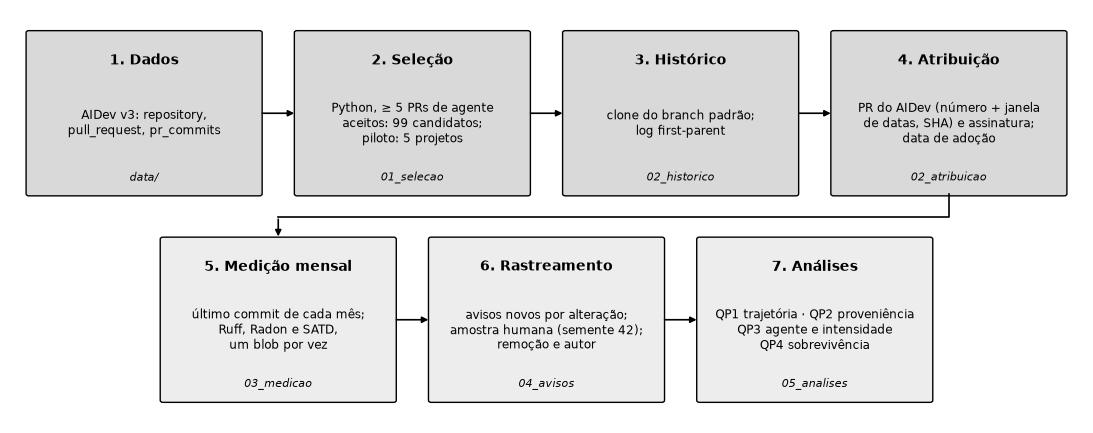

In [14]:
plt.rcParams.update({'font.size': 9, 'font.family': 'DejaVu Sans'})
n_cand = int((n_py >= 5).sum())
etapas = [
    ('1. Dados', 'AIDev v3: repository,\npull_request, pr_commits', 'data/'),
    ('2. Seleção', f'Python, ≥ 5 PRs de agente\naceitos: {n_cand} candidatos;\npiloto: {len(piloto)} projetos', '01_selecao'),
    ('3. Histórico', 'clone do branch padrão;\nlog first-parent', '02_historico'),
    ('4. Atribuição', 'PR do AIDev (número + janela\nde datas, SHA) e assinatura;\ndata de adoção', '02_atribuicao'),
    ('5. Medição mensal', 'último commit de cada mês;\nRuff, Radon e SATD,\num blob por vez', '03_medicao'),
    ('6. Rastreamento', 'avisos novos por alteração;\namostra humana (semente 42);\nremoção e autor', '04_avisos'),
    ('7. Análises', 'QP1 trajetória · QP2 proveniência\nQP3 agente e intensidade\nQP4 sobrevivência', '05_analises'),
]
fig, ax = plt.subplots(figsize=(11, 4.4)); ax.set_xlim(0, 4); ax.set_ylim(0, 2); ax.axis('off')
pos = [(0, 1), (1, 1), (2, 1), (3, 1), (0.5, 0), (1.5, 0), (2.5, 0)]
L, H = 0.86, 0.78
for (titulo, texto, nb), (x, y), cinza in zip(etapas, pos, ['0.85'] * 4 + ['0.93'] * 3):
    ax.add_patch(FancyBboxPatch((x + 0.07, y + 0.11), L, H, boxstyle='round,pad=0.01', fc=cinza, ec='black', lw=1))
    ax.text(x + 0.07 + L / 2, y + 0.11 + H - 0.1, titulo, ha='center', va='top', weight='bold', fontsize=10)
    ax.text(x + 0.07 + L / 2, y + 0.11 + H / 2 - 0.05, texto, ha='center', va='center', fontsize=8.5)
    ax.text(x + 0.07 + L / 2, y + 0.16, nb, ha='center', va='bottom', fontsize=8, style='italic')
seta = dict(arrowstyle='-|>', color='black', lw=1.2)
for i in range(3):
    ax.annotate('', xy=(pos[i + 1][0] + 0.07, 1.5), xytext=(pos[i][0] + 0.07 + L, 1.5), arrowprops=seta)
for i in range(4, 6):
    ax.annotate('', xy=(pos[i + 1][0] + 0.07, 0.5), xytext=(pos[i][0] + 0.07 + L, 0.5), arrowprops=seta)
x5 = pos[4][0] + 0.07 + L / 2
ax.plot([3.5, 3.5, x5], [1.11, 1.0, 1.0], color='black', lw=1.2)
ax.annotate('', xy=(x5, 0.89), xytext=(x5, 1.0), arrowprops=seta)
fig.tight_layout(); fig.savefig('../out/figs/fig1_pipeline.png', dpi=200)
plt.show()

**O que esta célula faz.** Desenha a Figura 3 a partir de `qp2_taxas.csv`: avisos novos e complexidade nova por KLOC adicionada em cada grupo de arquivos, com a KLOC adicionada anotada e hachura nos grupos com menos de 5 KLOC adicionada.

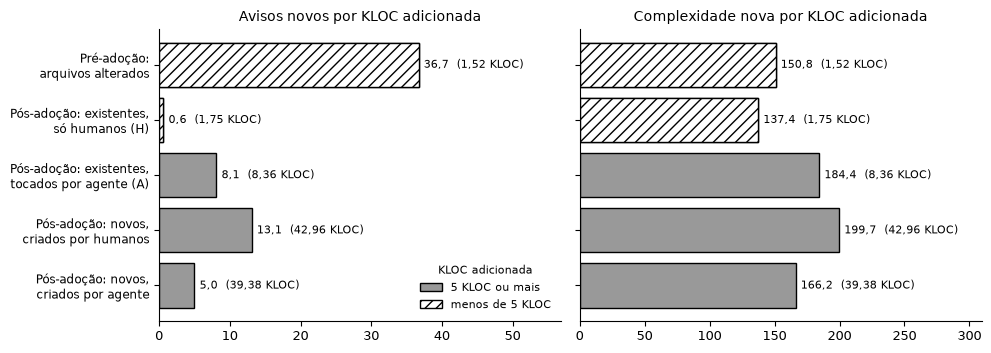

In [15]:
q2 = pd.read_csv('../out/qp2_taxas.csv')
rot = {'Pré-adoção: alterados': 'Pré-adoção:\narquivos alterados', 'Pós: existentes, só humanos (H)': 'Pós-adoção: existentes,\nsó humanos (H)',
       'Pós: existentes, tocados por agente (A)': 'Pós-adoção: existentes,\ntocados por agente (A)',
       'Pós: novos, criados por humanos': 'Pós-adoção: novos,\ncriados por humanos', 'Pós: novos, criados por agente': 'Pós-adoção: novos,\ncriados por agente'}
fmt = FuncFormatter(lambda v, _: f'{v:g}'.replace('.', ','))
fig, eixos = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
y = np.arange(len(q2))[::-1]
for ax, col, tit in zip(eixos, ['avisos novos por KLOC', 'complexidade nova por KLOC'],
                        ['Avisos novos por KLOC adicionada', 'Complexidade nova por KLOC adicionada']):
    pequeno = q2['KLOC adicionada'] < 5
    ax.barh(y, q2[col], color=np.where(pequeno, 'white', '0.6'), edgecolor='black', hatch=None)
    ax.barh(y[pequeno], q2[col][pequeno], color='white', edgecolor='black', hatch='///')
    for yi, v, k in zip(y, q2[col], q2['KLOC adicionada']):
        ax.text(v + q2[col].max() * 0.02, yi, f'{virg(v)}  ({virg(k, 2)} KLOC)', va='center', fontsize=8)
    ax.set_title(tit, fontsize=10); ax.set_xlim(0, q2[col].max() * 1.55); ax.xaxis.set_major_formatter(fmt)
    ax.spines[['top', 'right']].set_visible(False)
eixos[0].set_yticks(y); eixos[0].set_yticklabels([rot[g] for g in q2.grupo], fontsize=8.5)
eixos[0].legend(handles=[Patch(fc='0.6', ec='black', label='5 KLOC ou mais'), Patch(fc='white', ec='black', hatch='///', label='menos de 5 KLOC')],
                title='KLOC adicionada', frameon=False, fontsize=8, title_fontsize=8, loc='lower right')
fig.tight_layout(); fig.savefig('../out/figs/qp2_taxas.png', dpi=200)
plt.show()

**O que esta célula faz.** Desenha a Figura 4 a partir de `qp3_por_agente.csv`: avisos novos por KLOC adicionada de cada agente e da amostra humana, com o número de alterações e a KLOC adicionada anotados e hachura nos autores com menos de 1 KLOC adicionada.

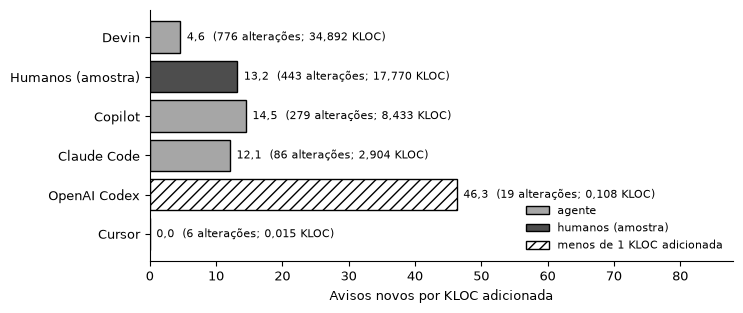

In [16]:
q3 = pd.read_csv('../out/qp3_por_agente.csv')
nomes = {'Claude_Code': 'Claude Code', 'OpenAI_Codex': 'OpenAI Codex', 'Humano': 'Humanos (amostra)'}
q3['rot'] = q3.ator.map(lambda a: nomes.get(a, a))
q3 = q3.sort_values('kloc_adicionada')
fig, ax = plt.subplots(figsize=(7.5, 3.2))
y = np.arange(len(q3))
pequeno = (q3.kloc_adicionada < 1).values
cor = np.where(q3.ator == 'Humano', '0.3', '0.65')
ax.barh(y[~pequeno], q3['avisos novos por KLOC'][~pequeno], color=cor[~pequeno], edgecolor='black')
ax.barh(y[pequeno], q3['avisos novos por KLOC'][pequeno], color='white', edgecolor='black', hatch='///')
for yi, v, k, n_ in zip(y, q3['avisos novos por KLOC'], q3.kloc_adicionada, q3.alteracoes):
    ax.text(v + 1, yi, f'{virg(v)}  ({n_} alterações; {virg(k, 3)} KLOC)', va='center', fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(q3.rot); ax.set_xlim(0, q3['avisos novos por KLOC'].max() * 1.9)
ax.set_xlabel('Avisos novos por KLOC adicionada'); ax.xaxis.set_major_formatter(fmt)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(handles=[Patch(fc='0.65', ec='black', label='agente'), Patch(fc='0.3', ec='black', label='humanos (amostra)'),
                   Patch(fc='white', ec='black', hatch='///', label='menos de 1 KLOC adicionada')], frameon=False, fontsize=8, loc='lower right')
fig.tight_layout(); fig.savefig('../out/figs/qp3_por_agente.png', dpi=200)
plt.show()